# Fase 2: o futuro dos *Enrolled*

No notebook principal, os 794 alunos *Enrolled* ficaram de fora porque ainda não têm desfecho. Eles continuavam matriculados depois do prazo normal do curso. Aqui a pergunta é outra: **se o padrão dos alunos com desfecho conhecido se mantiver, quantos deles devem evadir?** E com que confiança cada método responde?

**Ideia:**
- O grafo agora tem **todos os 4.424 alunos**. Os *Enrolled* entram como vértices **sem rótulo**. O grafo e o Leiden não usam o desfecho, então isso não vaza nada.
- **Leiden:** o *Enrolled* herda a **taxa de evasão da sua comunidade**, calculada só com os alunos de desfecho conhecido. É a resposta "pelos parecidos com ele".
- **GNN (GraphSAGE):** treinada nos alunos conhecidos, dá P(evadir) para cada *Enrolled*. O MLP sem arestas entra como referência.
- **"X% de certeza":** não existe gabarito para os *Enrolled*. A confiança é medida nos **alunos conhecidos**, com validação cruzada de 5 dobras: o modelo é **calibrado** se, quando diz 70%, acontecem 70%. Isso é o que dá para afirmar.

**Cuidado:** os *Enrolled* são alunos atrasados, um grupo diferente dos que serviram de treino. A previsão vale *se o padrão se mantiver*. Não é uma sentença sobre o aluno.

In [1]:
# %pip install gower igraph leidenalg torch torch_geometric scikit-learn pandas matplotlib
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gower, igraph as ig, leidenalg as la
import torch, torch.nn.functional as F
from torch_geometric.nn.models import GraphSAGE, MLP
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, normalized_mutual_info_score as NMI
from scipy.stats import chi2_contingency

# ===== PARÂMETROS (iguais para as 4 variações) =====
K = 40                                     # vizinhos do kNN mútuo
JANELAS_RODAR = ["1_matricula", "3_fim_1sem"]
N_PERM = 1000                              # permutações do teste do Leiden
DOBRAS = 5                                 # validação cruzada da GNN
SEED = 42
torch.use_deterministic_algorithms(True); torch.set_num_threads(1)   # GNN reprodutível na mesma máquina
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import random, os
from IPython.display import Image, display
from matplotlib.collections import LineCollection
from PIL import Image as PILImage
LARGURA = 6.3                                              # largura útil da página (in), para as figuras do artigo
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8})
os.makedirs("figuras", exist_ok=True); os.makedirs("resultados", exist_ok=True)

## 1. Dados: agora com os *Enrolled*

In [2]:
df = pd.read_csv("data.csv", sep=";")
NOMES = ["marital","app_mode","app_order","course","shift","prev_qual","prev_grade","nationality",
         "mother_qual","father_qual","mother_occ","father_occ","admission_grade","displaced",
         "special_needs","debtor","tuition_ok","gender","scholarship","age","international",
         "s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval",
         "s2_credited","s2_enrolled","s2_evaluations","s2_approved","s2_grade","s2_without_eval",
         "unemployment","inflation","gdp","target"]
df.columns = NOMES
alvo = df.pop("target")
y = alvo.map({"Dropout": 1, "Graduate": 0, "Enrolled": -1}).values     # -1 = ainda sem desfecho
CON = np.where(y >= 0)[0]; ENR = np.where(y < 0)[0]; N = len(df)
print(f"{N} alunos | {len(CON)} com desfecho (evasão {y[CON].mean():.1%}) | {len(ENR)} Enrolled sem desfecho")

CAT_BASE = ["marital","app_mode","shift","prev_qual","nationality","mother_qual","father_qual",
            "mother_occ","father_occ","displaced","special_needs","gender","international"]
NUM_BASE = ["app_order","prev_grade","admission_grade","age"]
CAT_FIN  = CAT_BASE + ["debtor","tuition_ok","scholarship"]
NUM_S1   = ["s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval"]
JANELAS = {"1_matricula": (CAT_BASE, NUM_BASE), "3_fim_1sem": (CAT_FIN, NUM_BASE + NUM_S1)}
for c in CAT_FIN:                                          # mesma regra do principal, agora na população toda
    vc = df[c].value_counts()
    df[c] = df[c].where(df[c].isin(vc[vc >= 30].index), -1)

4424 alunos | 3630 com desfecho (evasão 39.1%) | 794 Enrolled sem desfecho


### Os *Enrolled* são diferentes?
Médias de alguns indicadores nos três grupos. Se os *Enrolled* ficam no meio do caminho entre quem evadiu e quem se formou, a previsão faz sentido. Se ficam fora da faixa dos dois, o modelo está extrapolando.

In [3]:
grupo = alvo.map({"Dropout": "evadiu", "Graduate": "formou", "Enrolled": "Enrolled"})
comp = pd.DataFrame({
    "idade": df.age, "nota de admissão": df.admission_grade, "1º sem: aprovadas": df.s1_approved,
    "1º sem: nota": df.s1_grade, "devedor (%)": 100 * (df.debtor == 1), "mensalidade atrasada (%)": 100 * (df.tuition_ok == 0),
    "bolsista (%)": 100 * (df.scholarship == 1)}).groupby(grupo).mean().T[["evadiu", "Enrolled", "formou"]].round(1)
display(comp)

target,evadiu,Enrolled,formou
idade,26.1,22.4,21.8
nota de admissão,125.0,125.5,128.8
1º sem: aprovadas,2.6,4.3,6.2
1º sem: nota,7.3,11.1,12.6
devedor (%),22.0,11.3,4.6
mensalidade atrasada (%),32.2,5.3,1.3
bolsista (%),9.4,16.4,37.8


## 2. Distâncias, grafo e funções (iguais às do notebook principal)

In [4]:
def dist_gower(cats, nums):
    X = pd.concat([df[cats].astype(str), df[nums].astype(float)], axis=1)
    return gower.gower_matrix(X, cat_features=[True] * len(cats) + [False] * len(nums))

def dist_associacao(cats, nums):
    D = np.zeros((N, N))
    # categóricas: perfil de cada categoria nas outras variáveis -> TVD entre perfis
    codes = [pd.Categorical(df[c]).codes for c in cats]
    Q = [c.max() + 1 for c in codes]; pos = np.cumsum([0] + Q); m = len(cats)
    Z = np.zeros((N, sum(Q)))
    for j, c in enumerate(codes): Z[np.arange(N), pos[j] + c] = 1
    ZZ = Z.T @ Z; np.fill_diagonal(ZZ, 0)
    P = ZZ / np.maximum(Z.sum(0)[:, None], 1)
    for j, c in enumerate(codes):
        Pj = P[pos[j]:pos[j + 1]]
        delta = np.abs(Pj[:, None, :] - Pj[None, :, :]).sum(-1) / (2 * (m - 1))
        f = np.bincount(c, minlength=Q[j]) / N
        media = f @ delta @ f
        if media > 0: D += delta[c[:, None], c[None, :]] / media      # comensurável
    # numéricas: padroniza + PCA completo, cada componente dividido pela sua distância média
    X = df[nums].to_numpy(float); X = (X - X.mean(0)) / X.std(0, ddof=1)
    X = X @ np.linalg.svd(X, full_matrices=False)[2].T
    for k in range(X.shape[1]):
        dk = np.abs(X[:, k, None] - X[None, :, k]); D += dk / dk.mean()
    return D.astype(np.float32)

DISTANCIAS = {"Gower": dist_gower, "Associação": dist_associacao}

In [5]:
def knn_mutuo(D, k=K):
    Dm = np.round(D, 6); np.fill_diagonal(Dm, np.inf)       # arredonda: empates exatos em qualquer máquina
    viz = np.argsort(Dm, axis=1, kind="stable")[:, :k]    # empate desfeito pelo índice do aluno
    A = np.zeros((N, N), bool); A[np.repeat(np.arange(N), k), viz.ravel()] = True
    i, j = np.where(np.triu(A & A.T, 1))
    return i, j, np.maximum(1 - D[i, j] / D.max(), 1e-3)

In [6]:
def atributos(cats, nums):
    oh = pd.get_dummies(df[cats].astype(str), dtype=np.float32).values
    num = df[nums].to_numpy(np.float32); num = (num - num.mean(0)) / num.std(0)
    return torch.tensor(np.hstack([oh, num]))

def treina(model, X, ei, tr, va, epocas=300, paciencia=30):
    yt = torch.tensor(y)
    peso = torch.tensor(len(tr) / (2 * np.bincount(y[tr])), dtype=torch.float32)   # compensa 39% evadiu x 61% formou
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    melhor, estado, sem = -1, None, 0
    for _ in range(epocas):
        model.train(); opt.zero_grad()
        F.cross_entropy(model(X, ei)[tr], yt[tr], weight=peso).backward(); opt.step()
        model.eval()
        with torch.no_grad(): f = f1_score(y[va], model(X, ei)[va].argmax(1), average="macro")
        if f > melhor: melhor, estado, sem = f, {k: v.clone() for k, v in model.state_dict().items()}, 0
        elif (sem := sem + 1) >= paciencia: break
    model.load_state_dict(estado); model.eval()
    with torch.no_grad(): return F.softmax(model(X, ei), 1)[:, 1].numpy()     # P(evadiu)

class SemArestas(torch.nn.Module):          # MLP do PyG com a mesma assinatura da GNN
    def __init__(self, d): super().__init__(); self.m = MLP(in_channels=d, hidden_channels=64, out_channels=2, num_layers=2, dropout=0.5, norm=None)
    def forward(self, x, ei): return self.m(x)

def roda_gnn(i, j, cats, nums):
    X = atributos(cats, nums)
    ei = torch.tensor(np.vstack([np.r_[i, j], np.r_[j, i]]), dtype=torch.long)
    linhas, oof = [], {"GraphSAGE": np.zeros(N), "MLP (sem arestas)": np.zeros(N)}
    for f, (trv, te) in enumerate(StratifiedKFold(DOBRAS, shuffle=True, random_state=SEED).split(X, y)):
        tr, va = train_test_split(trv, test_size=0.15, stratify=y[trv], random_state=f)
        modelos = {"GraphSAGE": GraphSAGE(X.shape[1], 64, num_layers=2, out_channels=2, dropout=0.5),
                   "MLP (sem arestas)": SemArestas(X.shape[1])}
        for nome, mod in modelos.items():
            torch.manual_seed(f); p = treina(mod, X, ei, tr, va); oof[nome][te] = p[te]
            linhas.append(dict(modelo=nome, dobra=f, F1=f1_score(y[te], p[te] > .5, average="macro"), AUC=roc_auc_score(y[te], p[te])))
        Xn = X.numpy(); lr = LogisticRegression(max_iter=3000, class_weight="balanced").fit(Xn[trv], y[trv])
        p = lr.predict_proba(Xn[te])[:, 1]
        linhas.append(dict(modelo="Logística", dobra=f, F1=f1_score(y[te], p > .5, average="macro"), AUC=roc_auc_score(y[te], p)))
    return pd.DataFrame(linhas), oof              # oof = P(evadiu) de cada aluno, prevista sem ele no treino

## 3. Os dois métodos prevendo

Para cada janela e distância:
1. Monta o grafo dos 4.424 alunos e roda o Leiden uma vez (o Leiden não usa o desfecho).
2. Faz validação cruzada de 5 dobras **nos alunos conhecidos**. Em cada dobra, o Leiden prevê com a taxa da comunidade calculada só no treino, e a GNN e o MLP treinam só no treino. Isso gera uma previsão "honesta" para cada aluno conhecido, usada para medir a calibração.
3. **Previsão para os Enrolled:** no Leiden, a taxa da comunidade com todos os conhecidos; na GNN e no MLP, a média dos 5 modelos das dobras.

A taxa da comunidade é suavizada para a taxa geral (equivale a somar 5 alunos "médios" a cada comunidade). Assim, comunidades pequenas não dão 0% ou 100% por acaso.

A GNN e o MLP treinam com peso de classes, o que faz o modelo agir como se a evasão fosse 50%. As probabilidades são corrigidas de volta para a taxa real (39%) com a correção de prior, uma fórmula fechada: p' = p·π / (p·π + (1−p)(1−π)). Sem isso, a GNN superestima o risco.

In [7]:
def particao_leiden(i, j, w):
    g = ig.Graph(n=N, edges=list(zip(i, j))); g.es["weight"] = w
    return np.array(la.find_partition(g, la.ModularityVertexPartition, weights="weight", seed=0).membership)

def prob_leiden(memb, treino, a=5):
    geral = y[treino].mean()
    s = pd.Series(y[treino]).groupby(memb[treino]).agg(["sum", "count"])
    taxa = (s["sum"] + a * geral) / (s["count"] + a)
    return pd.Series(memb).map(taxa).fillna(geral).to_numpy()

def corrige_prior(p, pi):
    # o treino usa peso de classes (o modelo "enxerga" 50% de evasão); isto devolve a probabilidade para a taxa real pi
    return p * pi / (p * pi + (1 - p) * (1 - pi))

def ece(yv, p, bins=10):                                    # erro de calibração esperado: |previsto − observado| médio
    b = np.minimum((p * bins).astype(int), bins - 1)
    return sum(abs(p[b == k].mean() - yv[b == k].mean()) * (b == k).mean() for k in range(bins) if (b == k).any())

def roda(jan, dist):
    cats, nums = JANELAS[jan]
    D = DISTANCIAS[dist](cats, nums); i, j, w = knn_mutuo(D)
    memb = particao_leiden(i, j, w)
    X = atributos(cats, nums)
    ei = torch.tensor(np.vstack([np.r_[i, j], np.r_[j, i]]), dtype=torch.long)
    oof = {m: np.zeros(N) for m in ["Leiden", "GNN", "MLP"]}; enr = {m: np.zeros(N) for m in ["GNN", "MLP"]}
    for f, (a, b) in enumerate(StratifiedKFold(DOBRAS, shuffle=True, random_state=SEED).split(CON, y[CON])):
        trv, te = CON[a], CON[b]
        oof["Leiden"][te] = prob_leiden(memb, trv)[te]
        tr, va = train_test_split(trv, test_size=0.15, stratify=y[trv], random_state=f)
        for nome, mod in {"GNN": GraphSAGE(X.shape[1], 64, num_layers=2, out_channels=2, dropout=0.5),
                          "MLP": SemArestas(X.shape[1])}.items():
            torch.manual_seed(f); p = corrige_prior(treina(mod, X, ei, tr, va), y[tr].mean())
            oof[nome][te] = p[te]; enr[nome] += p / DOBRAS
    enr["Leiden"] = prob_leiden(memb, CON)
    return dict(arestas=(i, j, w), memb=memb, oof=oof, enr=enr)

RES = {}
for jan in JANELAS_RODAR:
    for dist in DISTANCIAS:
        RES[jan, dist] = roda(jan, dist)
        print(f"{jan:12s} {dist:10s} ok | comunidades ≥30: {(np.bincount(RES[jan, dist]['memb']) >= 30).sum()}")

1_matricula  Gower      ok | comunidades ≥30: 13


1_matricula  Associação ok | comunidades ≥30: 19


3_fim_1sem   Gower      ok | comunidades ≥30: 12


3_fim_1sem   Associação ok | comunidades ≥30: 18


## 4. Quanto dá para confiar? (medido nos alunos conhecidos)

- **AUC:** o quanto o método ordena bem o risco (0,5 = chute, 1 = perfeito).
- **Brier:** erro quadrático da probabilidade (menor é melhor; prever sempre 39% dá ≈ 0,24).
- **ECE:** distância média entre a probabilidade prevista e a frequência observada. Um ECE de 0,03 quer dizer que "70%" significa, na prática, entre 67% e 73%.
- **Evasões esperadas:** a soma das probabilidades dos 794 *Enrolled*, ou seja, quantos devem evadir *se o padrão se mantiver*. Os contadores de alto (P ≥ 0,7) e baixo (P ≤ 0,3) risco servem para priorizar apoio.

In [8]:
linhas = []
for (jan, dist), r in RES.items():
    for m in ["Leiden", "GNN", "MLP"]:
        p, yv = r["oof"][m][CON], y[CON]; pe = r["enr"][m][ENR]
        linhas.append({"janela": jan, "distância": dist, "método": m,
                       "AUC": roc_auc_score(yv, p), "Brier": brier_score_loss(yv, p), "ECE": ece(yv, p),
                       "Enrolled: evasões esperadas": round(pe.sum()), "Enrolled: % esperado": pe.mean(),
                       "Enrolled: alto risco (P≥0,7)": int((pe >= 0.7).sum()), "Enrolled: baixo risco (P≤0,3)": int((pe <= 0.3).sum())})
tab = pd.DataFrame(linhas).round(3)
tab.to_csv("resultados/enrolled_resumo.csv", index=False)
display(tab)

,janela,distância,método,AUC,Brier,ECE,Enrolled: evasões esperadas,Enrolled: % esperado,"Enrolled: alto risco (P≥0,7)","Enrolled: baixo risco (P≤0,3)"
0,1_matricula,Gower,Leiden,0.680,0.215,0.016,295,0.371,0,314
1,1_matricula,Gower,GNN,0.730,0.202,0.027,286,0.360,31,356
2,1_matricula,Gower,MLP,0.730,0.202,0.028,292,0.367,32,335
3,1_matricula,Associação,Leiden,0.689,0.212,0.017,299,0.376,0,282
4,1_matricula,Associação,GNN,0.738,0.199,0.029,280,0.352,30,367
5,1_matricula,Associação,MLP,0.736,0.200,0.026,299,0.377,36,316
6,3_fim_1sem,Gower,Leiden,0.757,0.184,0.017,285,0.358,45,307
7,3_fim_1sem,Gower,GNN,0.922,0.096,0.028,328,0.413,199,381
8,3_fim_1sem,Gower,MLP,0.922,0.096,0.026,327,0.412,190,382
9,3_fim_1sem,Associação,Leiden,0.820,0.162,0.008,285,0.359,110,372


### A tabela "quando o método diz X%, acontece Y%"
Alunos conhecidos agrupados pela probabilidade prevista (fora da dobra), comparada com a evasão que de fato aconteceu. Esse é o "X% de certeza" que dá para defender.

In [9]:
faixas = [0, .2, .4, .6, .8, 1.0001]; rot = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]
blocos = []
for (jan, dist), r in RES.items():
    for m in ["Leiden", "GNN"]:
        p = r["oof"][m][CON]; f = pd.cut(p, faixas, labels=rot, right=False)
        t = pd.DataFrame({"faixa": f, "evadiu": y[CON]}).groupby("faixa", observed=False)["evadiu"].agg(["size", "mean"])
        nE = pd.Series(pd.cut(r["enr"][m][ENR], faixas, labels=rot, right=False)).value_counts().reindex(rot).fillna(0).astype(int)
        blocos.append(pd.DataFrame({"janela": jan, "distância": dist, "método": m, "faixa prevista": rot,
                                    "conhecidos": t["size"].values, "evasão observada": t["mean"].round(2).values,
                                    "Enrolled nessa faixa": nE.values}))
calib = pd.concat(blocos); calib.to_csv("resultados/enrolled_calibracao.csv", index=False)
display(calib[calib.janela == "3_fim_1sem"])

,janela,distância,método,faixa prevista,conhecidos,evasão observada,Enrolled nessa faixa
0,3_fim_1sem,Gower,Leiden,0–20%,831,0.15,151
1,3_fim_1sem,Gower,Leiden,20–40%,1519,0.32,475
2,3_fim_1sem,Gower,Leiden,40–60%,797,0.48,123
3,3_fim_1sem,Gower,Leiden,60–80%,135,0.72,4
4,3_fim_1sem,Gower,Leiden,80–100%,348,0.95,41
0,3_fim_1sem,Gower,GNN,0–20%,1959,0.09,305
1,3_fim_1sem,Gower,GNN,20–40%,332,0.28,139
2,3_fim_1sem,Gower,GNN,40–60%,177,0.47,117
3,3_fim_1sem,Gower,GNN,60–80%,172,0.66,83
4,3_fim_1sem,Gower,GNN,80–100%,990,0.96,150


## 5. Figuras (uma por arquivo, para o artigo)

As figuras ficam em `figuras/` como PDF (pontos rasterizados) e PNG de 300 dpi:
- **08 – Calibração:** quando o método diz X%, quanto acontece. (a) Leiden, (b) GNN. Linha cheia = Gower, tracejada = Associação. Quanto mais perto da diagonal, mais dá para confiar no número.
- **09 – Distribuição do risco previsto para os Enrolled:** (a) Leiden, (b) GNN.
- **10 – Os Enrolled no grafo:** alunos conhecidos em cinza; *Enrolled* coloridos pelo risco previsto pela GNN.

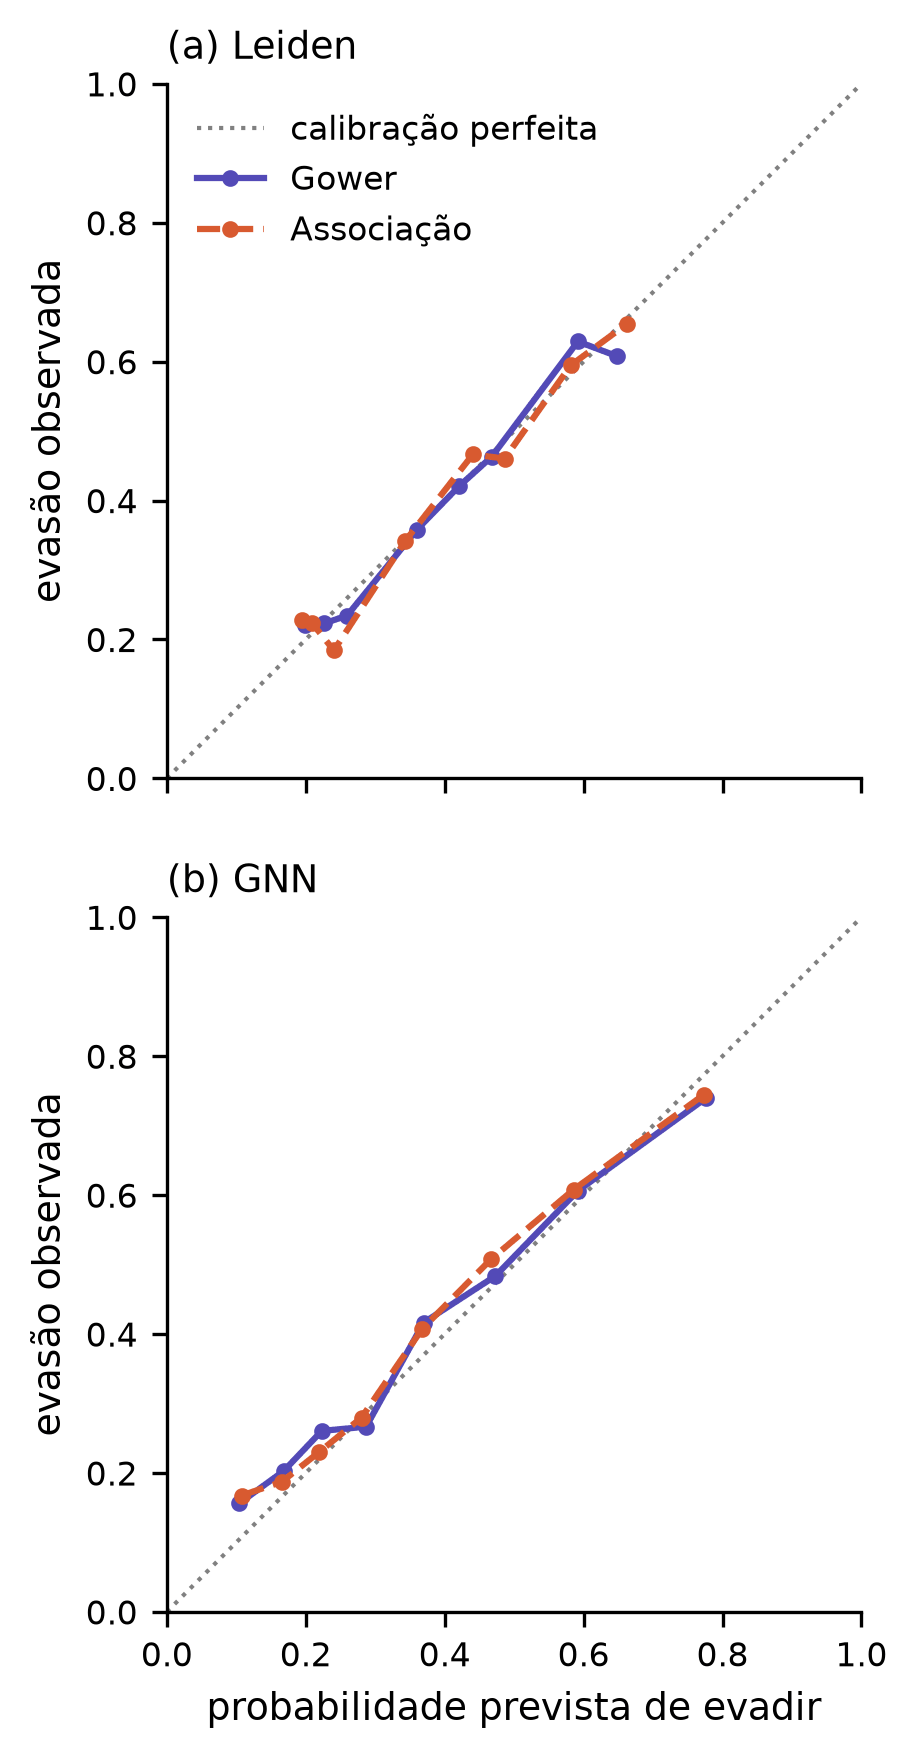

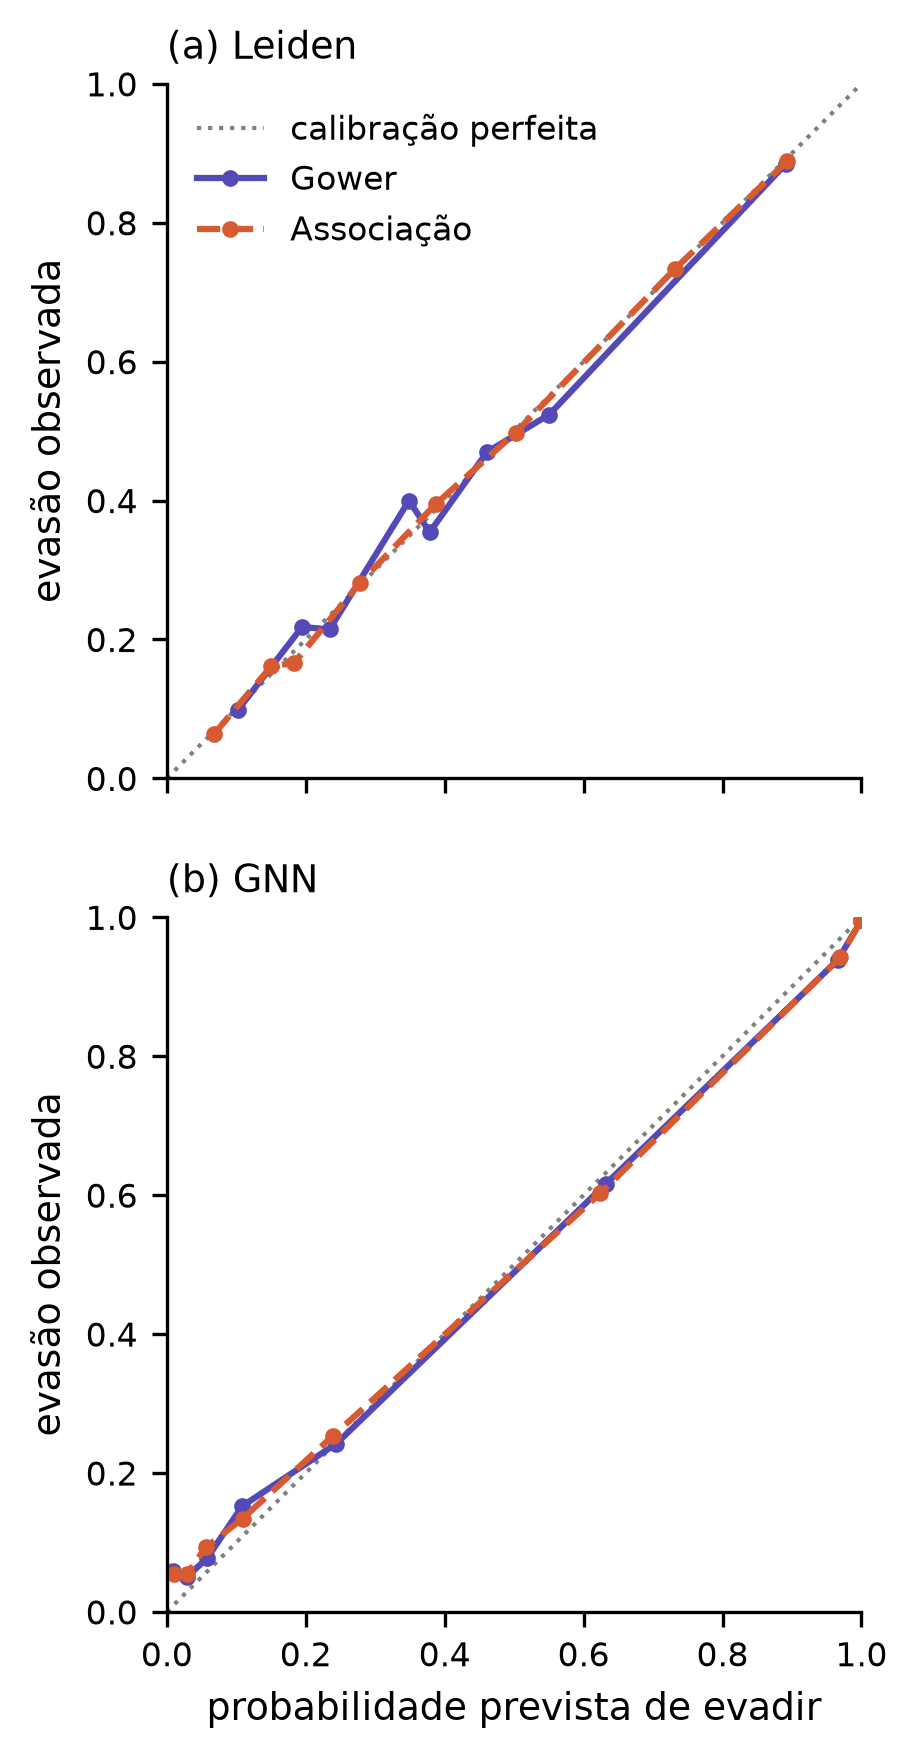

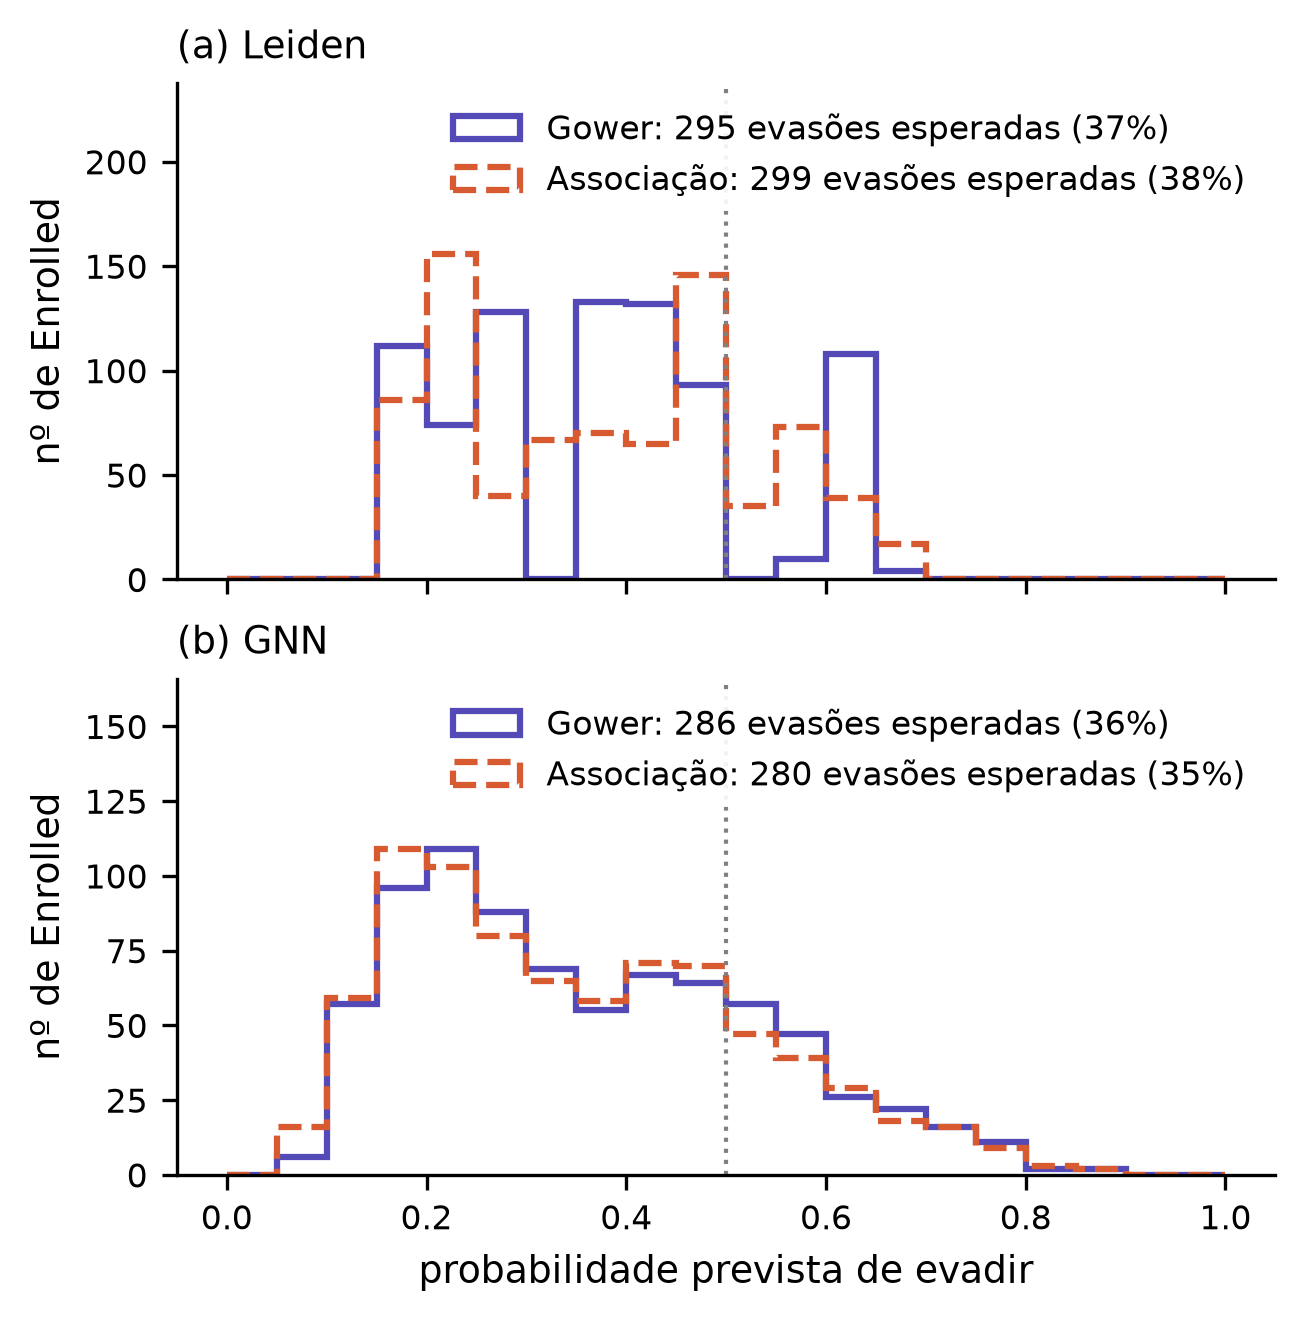

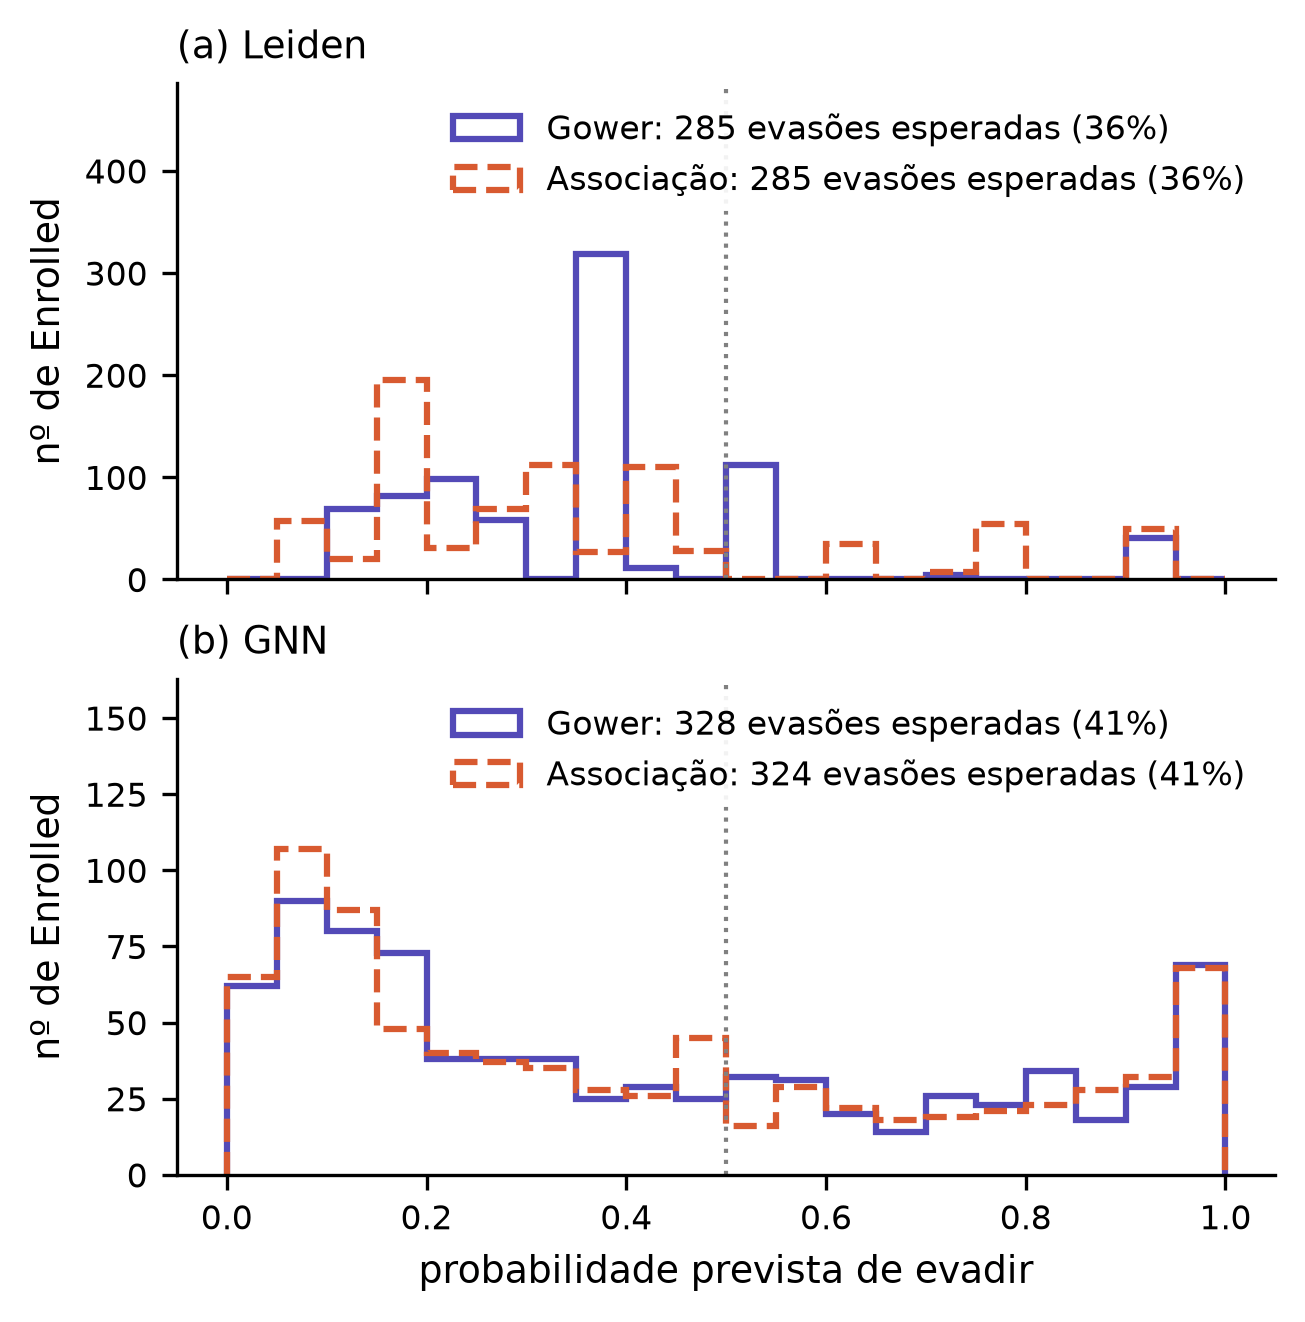

In [10]:
CORES_D = {"Gower": "#534AB7", "Associação": "#D85A30"}; ESTILO = {"Gower": "-", "Associação": "--"}
RISCO = plt.get_cmap("RdYlGn_r"); SLUG = {"Gower": "gower", "Associação": "associacao"}

def salva(fig, nome):
    fig.savefig(f"figuras/{nome}.pdf", bbox_inches="tight", dpi=300)
    fig.savefig(f"figuras/{nome}.png", bbox_inches="tight", dpi=300); plt.close(fig)
    PILImage.open(f"figuras/{nome}.png").convert("RGB").quantize(256, method=PILImage.Quantize.MEDIANCUT).save(f"figuras/{nome}.png", optimize=True)
    display(Image(f"figuras/{nome}.png", width=700))

for jan in JANELAS_RODAR:
    fig, axs = plt.subplots(2, 1, figsize=(LARGURA * 0.6, LARGURA * 1.05), sharex=True)
    for ax, m, letra in zip(axs, ["Leiden", "GNN"], "ab"):
        ax.plot([0, 1], [0, 1], ":", c="gray", lw=1, label="calibração perfeita")
        for dist in DISTANCIAS:
            obs, prev = calibration_curve(y[CON], RES[jan, dist]["oof"][m][CON], n_bins=8, strategy="quantile")
            ax.plot(prev, obs, ESTILO[dist], marker="o", ms=3, c=CORES_D[dist], label=dist)
        ax.set_ylabel("evasão observada"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
        ax.set_title(f"({letra}) {m}", loc="left"); ax.spines[["top", "right"]].set_visible(False)
    axs[1].set_xlabel("probabilidade prevista de evadir"); axs[0].legend(frameon=False, loc="upper left")
    salva(fig, f"08_enrolled_calibracao_{jan}")

for jan in JANELAS_RODAR:
    fig, axs = plt.subplots(2, 1, figsize=(LARGURA * 0.75, LARGURA * 0.75), sharex=True)
    for ax, m, letra in zip(axs, ["Leiden", "GNN"], "ab"):
        for dist in DISTANCIAS:
            pe = RES[jan, dist]["enr"][m][ENR]
            ax.hist(pe, bins=np.linspace(0, 1, 21), histtype="step", lw=1.5, ls=ESTILO[dist], color=CORES_D[dist],
                    label=f"{dist}: {pe.sum():.0f} evasões esperadas ({pe.mean():.0%})")
        ax.axvline(0.5, c="gray", ls=":", lw=1); ax.set_ylabel("nº de Enrolled"); ax.set_ylim(0, ax.get_ylim()[1] * 1.45)   # espaço para a legenda
        ax.set_title(f"({letra}) {m}", loc="left"); ax.legend(frameon=True, framealpha=0.9, edgecolor="none", loc="upper right"); ax.spines[["top", "right"]].set_visible(False)
    axs[1].set_xlabel("probabilidade prevista de evadir")
    salva(fig, f"09_enrolled_distribuicao_{jan}")

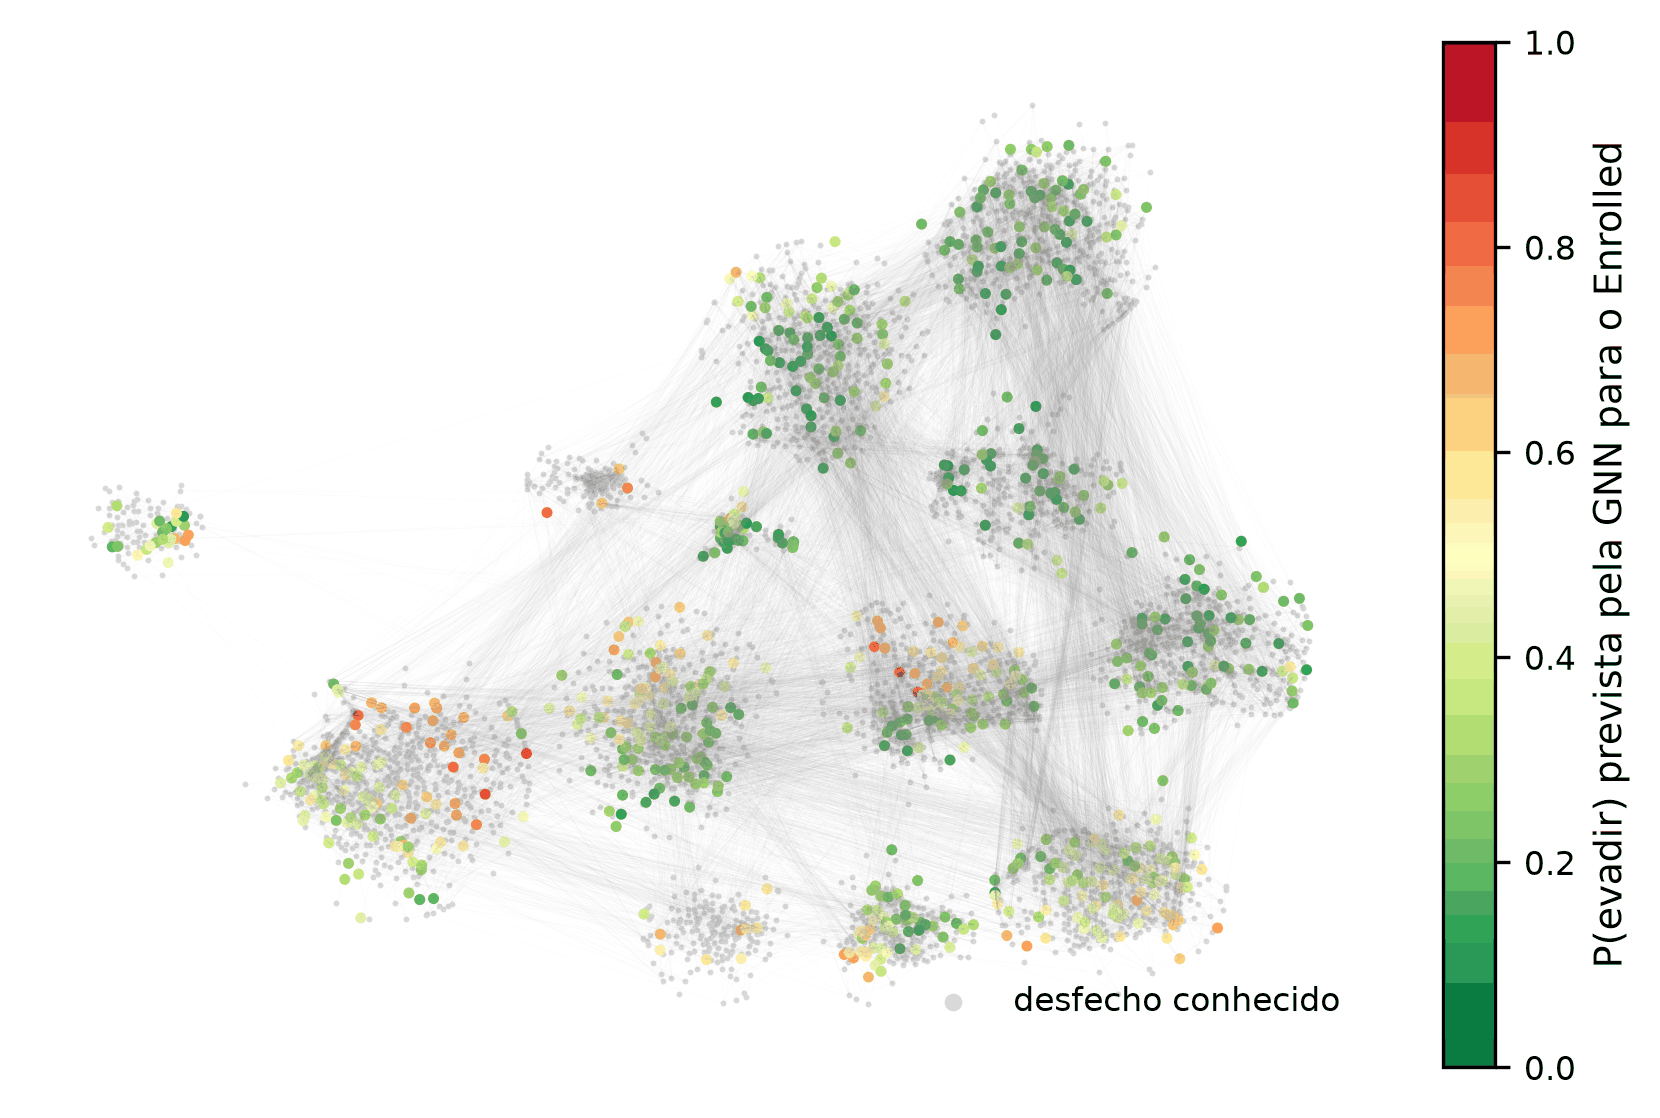

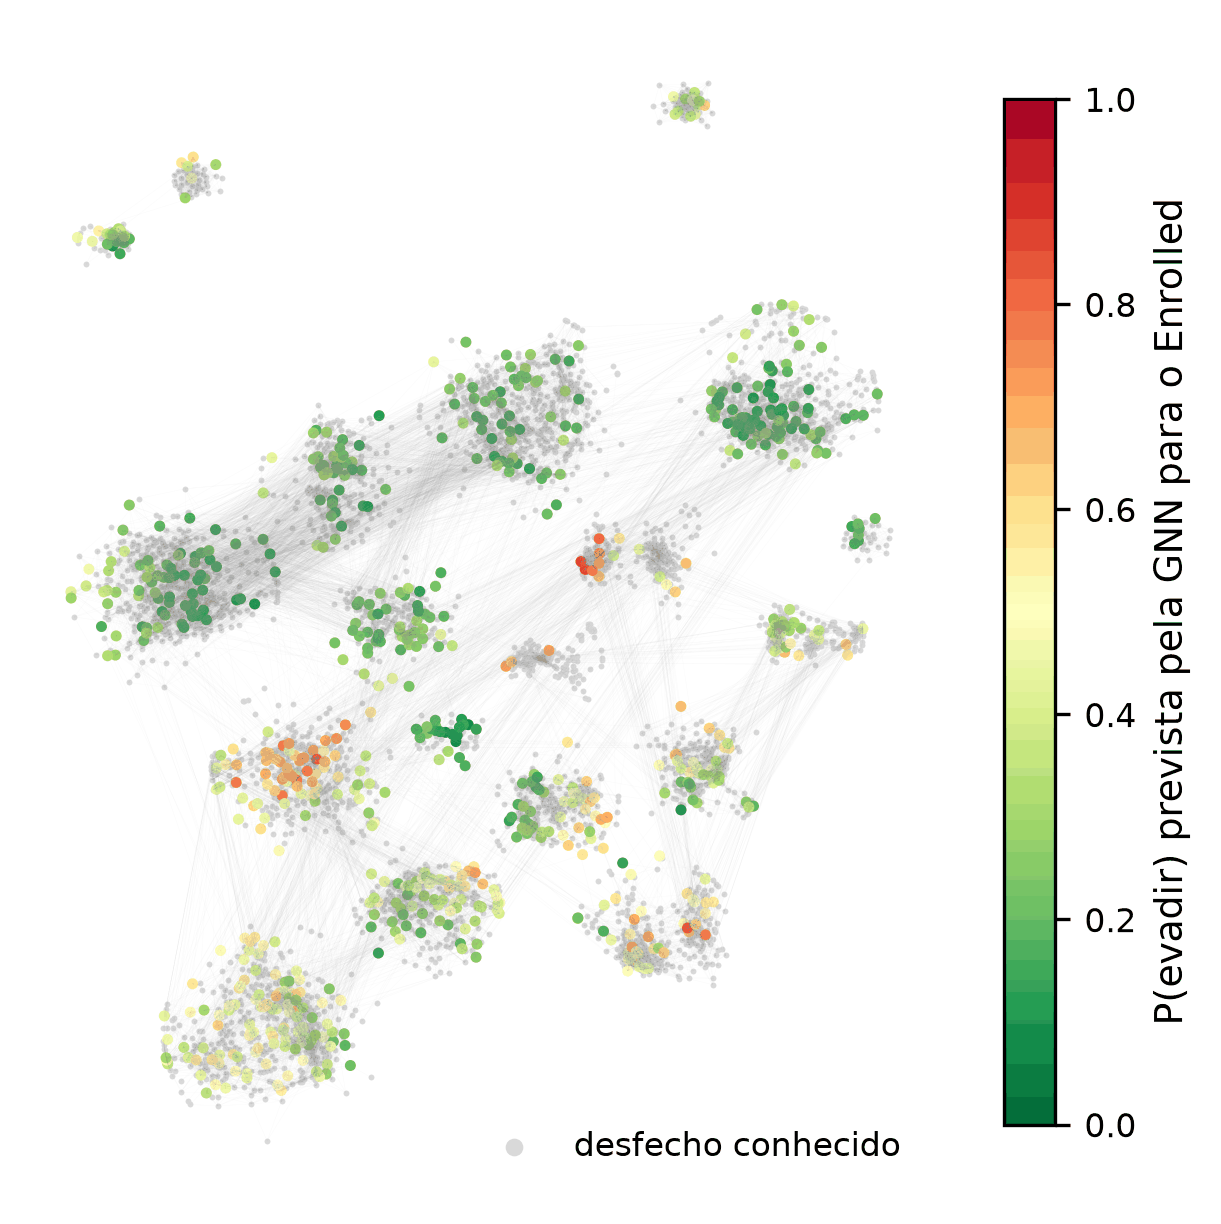

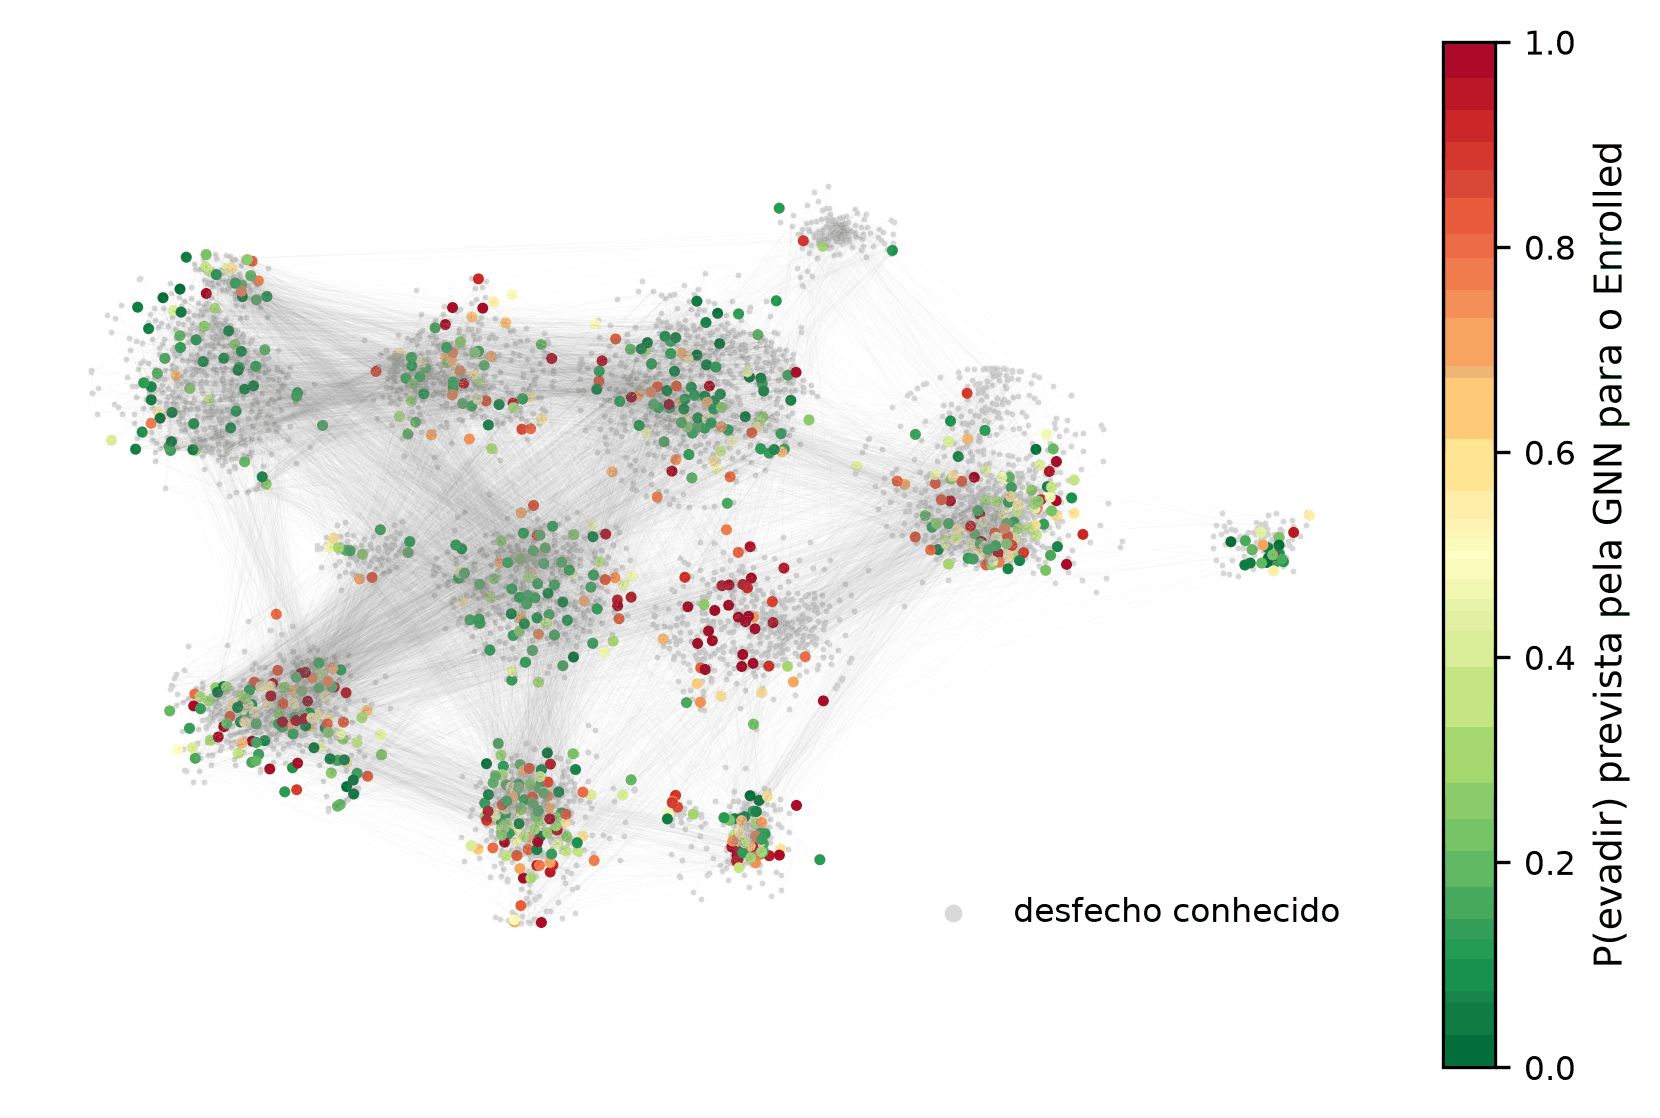

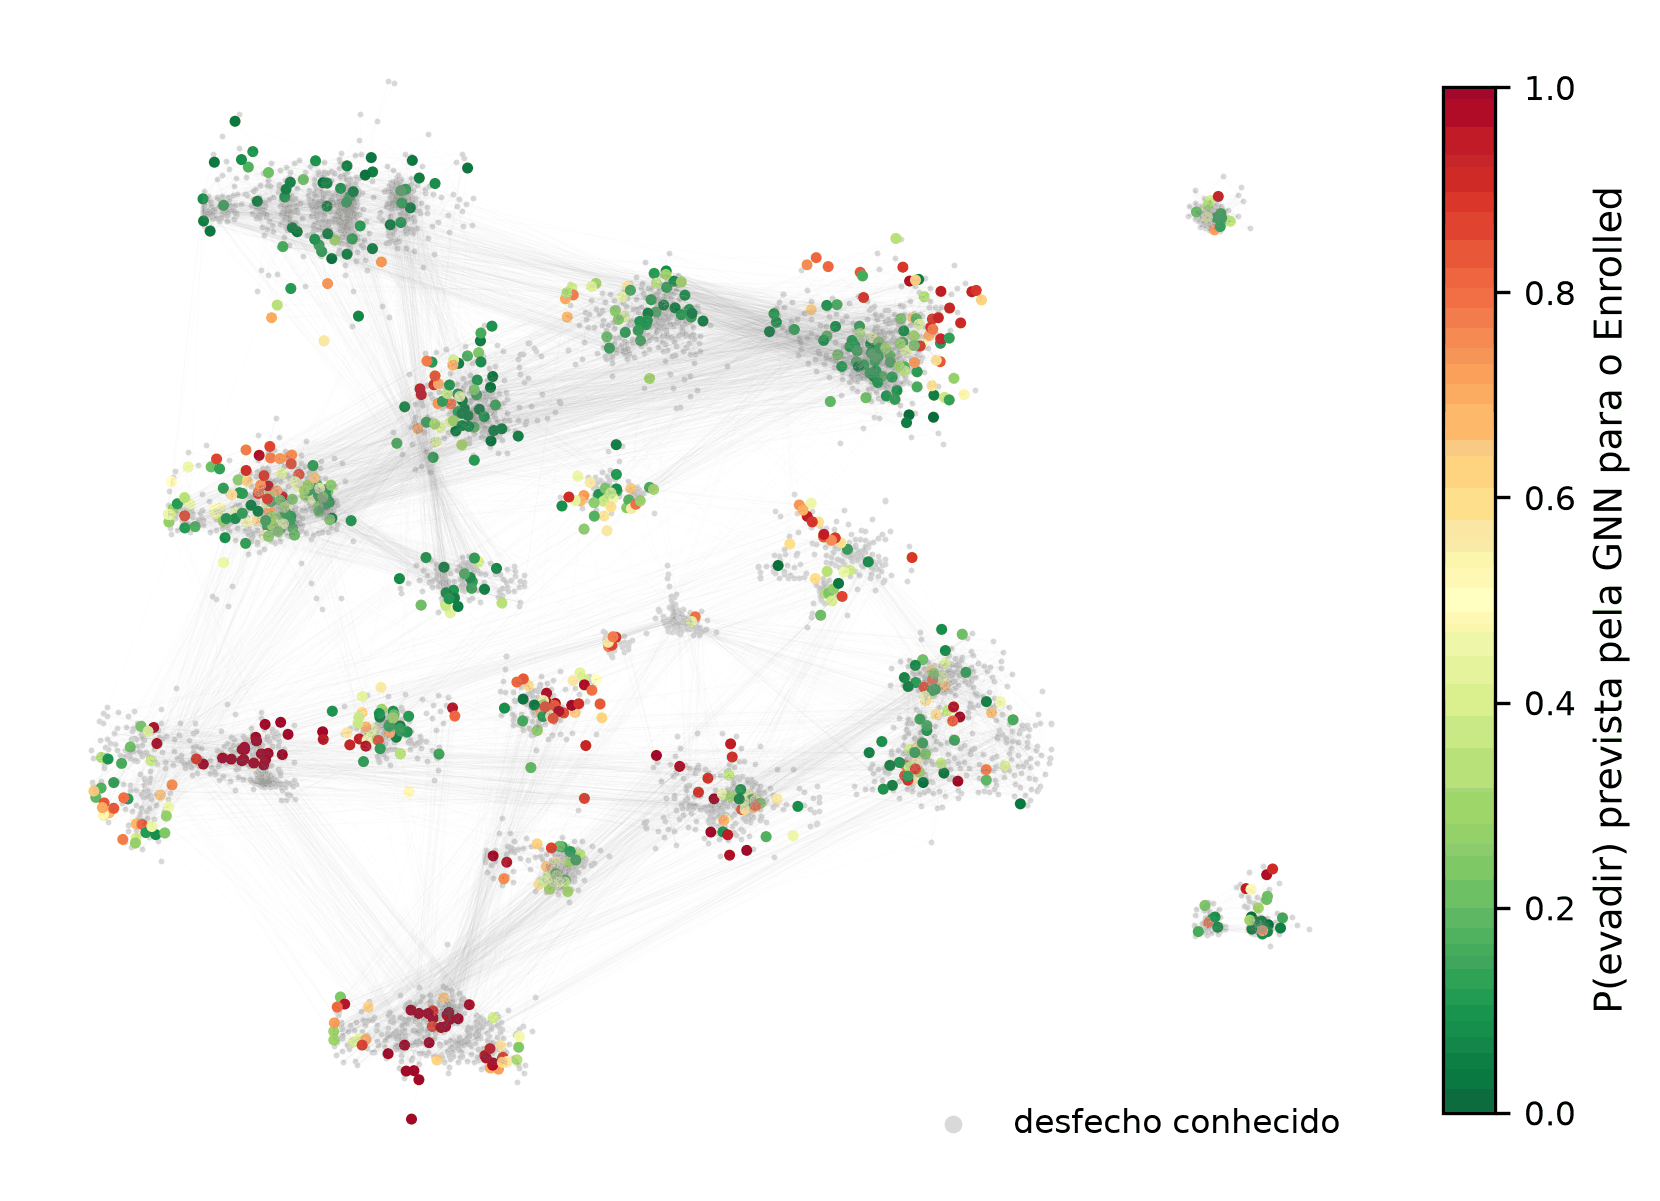

In [11]:
def posicoes(i, j, memb, seed=SEED):
    # layout em bolhas (o mesmo do notebook principal): comunidade = bolha; alunos de comunidades < 30 ficam fora (NaN)
    comms = [c for c in np.unique(memb) if (memb == c).sum() >= 30]; idx = {c: k for k, c in enumerate(comms)}; C = len(comms)
    tam = np.array([(memb == c).sum() for c in comms]); random.seed(seed)
    W = np.zeros((C, C)); m = np.isin(memb[i], comms) & np.isin(memb[j], comms) & (memb[i] != memb[j])
    np.add.at(W, (np.array([idx[c] for c in memb[i][m]], int), np.array([idx[c] for c in memb[j][m]], int)), 1); W = W + W.T
    gc = ig.Graph.Weighted_Adjacency(W.tolist(), mode="undirected", loops=False)
    cen = np.array(gc.layout_fruchterman_reingold(weights="weight" if gc.ecount() else None).coords)
    cen = (cen - cen.mean(0)) / (np.abs(cen - cen.mean(0)).max() + 1e-9); raio = 0.22 * np.sqrt(tam / tam.max())
    for _ in range(500):
        mexeu = False
        for a in range(C):
            for b in range(a + 1, C):
                d = cen[b] - cen[a]; dd = np.hypot(*d) + 1e-9; mn = raio[a] + raio[b] + 0.04
                if dd < mn: e = (mn - dd) / 2 * d / dd; cen[a] -= e; cen[b] += e; mexeu = True
        if not mexeu: break
    pos = np.full((N, 2), np.nan)
    for k, c in enumerate(comms):
        nos = np.where(memb == c)[0]; loc = {v: t for t, v in enumerate(nos)}; mm = (memb[i] == c) & (memb[j] == c)
        g = ig.Graph(n=len(nos), edges=[(loc[a], loc[b]) for a, b in zip(i[mm], j[mm])])
        p = np.array(g.layout_fruchterman_reingold(niter=300).coords); p -= np.median(p, 0)
        p = p / (np.percentile(np.hypot(p[:, 0], p[:, 1]), 95) + 1e-9); nr = np.hypot(p[:, 0], p[:, 1]); p[nr > 1] /= nr[nr > 1, None]
        pos[nos] = cen[k] + p * raio[k]
    return pos

for jan in JANELAS_RODAR:
    for dist in DISTANCIAS:
        r = RES[jan, dist]; i, j, _ = r["arestas"]; pos = posicoes(i, j, r["memb"]); ok = ~np.isnan(pos[:, 0]); e = ok[i] & ok[j]
        fig, ax = plt.subplots(figsize=(LARGURA, LARGURA * 0.8))
        ax.add_collection(LineCollection(np.stack([pos[i[e]], pos[j[e]]], 1), colors="#999999", linewidths=0.1, alpha=0.05, rasterized=True))
        con = np.intersect1d(CON, np.where(ok)[0]); en = np.intersect1d(ENR, np.where(ok)[0])
        ax.scatter(pos[con, 0], pos[con, 1], c="#d9d9d9", s=2, linewidths=0, rasterized=True, label="desfecho conhecido")
        sc = ax.scatter(pos[en, 0], pos[en, 1], c=r["enr"]["GNN"][en], cmap=RISCO, vmin=0, vmax=1, s=7, linewidths=0, rasterized=True)
        fig.colorbar(sc, ax=ax, fraction=0.035, label="P(evadir) prevista pela GNN para o Enrolled")
        ax.legend(frameon=False, loc="lower right", markerscale=3); ax.set_aspect("equal"); ax.axis("off"); ax.autoscale_view()
        salva(fig, f"10_enrolled_grafo_{jan}_{SLUG[dist]}")

## 6. Os métodos concordam sobre os Enrolled?
Correlação entre as probabilidades previstas, e o percentual de *Enrolled* que os dois métodos colocam do mesmo lado de 50%.

In [12]:
conc = []
for (jan, dist), r in RES.items():
    a, b = r["enr"]["Leiden"][ENR], r["enr"]["GNN"][ENR]
    conc.append({"janela": jan, "distância": dist, "correlação Leiden × GNN": np.corrcoef(a, b)[0, 1],
                 "mesmo lado de 50%": ((a > .5) == (b > .5)).mean()})
display(pd.DataFrame(conc).round(2))

,janela,distância,correlação Leiden × GNN,mesmo lado de 50%
0,1_matricula,Gower,0.60,0.77
1,1_matricula,Associação,0.74,0.81
2,3_fim_1sem,Gower,0.37,0.64
3,3_fim_1sem,Associação,0.48,0.72


## 7. Como ler

- **A previsão útil é a da matrícula.** No fim do 1º semestre, os *Enrolled* já mostram o próprio desempenho, e o risco previsto reflete isso.
- **Os números para os Enrolled valem *se o padrão dos conhecidos se mantiver*.** São alunos atrasados, um grupo que não estava no treino (ver a tabela da seção 1). Por isso, a "certeza" é a calibração medida nos conhecidos, não uma garantia sobre esses alunos.
- **Uso:** priorizar apoio (tutoria, contato, auxílio financeiro) para os *Enrolled* de alto risco. Nunca rotular nem tomar decisão automática sobre o aluno.